# DFlowNovo: Reproducibility & Benchmark Evaluation

This notebook reproduces the complete **DFlowNovo** de novo peptide sequencing pipeline:
1. **Training Demonstration on MassIVE-KB**: Continuous-time discrete flow matching with cosine schedule on a mini-chunk of the MassIVE-KB dataset (2 epochs).
2. **Production Checkpoint & KnapsackDP**: Loading the 59.5M parameter MassIVE-KB checkpoint with exact combinatorial reachability logit filtering.
3. **High-Throughput Inference (10,000 Spectra)**: Batched non-autoregressive reverse flow decoding with hybrid beam search ($T=0.0$ deterministic greedy + $T=0.7$ stochastic exploration) and detailed balance re-masking ($\eta = 0.15$).
4. **ListNet Candidate Reranking**: Extracting multi-modal MS/MS physical features (fragment ladders, coverage, terminal bonus, precursor $\Delta\text{ppm}$) and learning optimal candidate scoring via ListNet.
5. **Quantitative Metrics**: Measuring Peptide Accuracy (isobaric I/L match), Amino Acid Recall/Precision/F1, Precursor Mass Match ($\le 20\text{ ppm}$), and Decoding Throughput (spectra/second).
6. **Diagnostic Visualizations**: Generating precursor mass error distribution and length-stratified accuracy directly from empirical predictions.


In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

# Ensure project root and src are in python path
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from src.data.constants import AA_MASSES_DICT, M_H2O
from src.data.data import build_vocabulary, get_dataset, build_dataloader, spectrum_collate
from src.data.massive_kb import load_and_preprocess_shards
from src.train.factory import build_models
from src.train.io import load_checkpoint, load_models_from_checkpoint, infer_model_config_from_checkpoint
from src.flow_matching.sampling import sample_noising_step_mask
from src.flow_matching.scheduler import cosine_scheduler
from src.train.loss import peptide_loss, length_loss
from src.inference.knapsack_dp import ExactReachabilityDP
from src.inference.predict import predict_peptide, decode_tokens
from src.inference.reranker import CandidateReranker, extract_candidate_features
from src.eval.metrics import compute_denovo_metrics

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.set_float32_matmul_precision("high")
print(f"Hardware initialization: using {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


Hardware initialization: using cuda (NVIDIA H100 80GB HBM3)


## 1. Model Training Demo on MassIVE-KB

Here we demonstrate continuous-time discrete flow matching training on MassIVE-KB.

To make this completely machine-agnostic and fast to execute, you do not need the entire multi-gigabyte dataset. The helper below checks your local environment first (`data/massive_kb`, `/dev/shm/massive_kb`, or local cache) and downloads **only a single parquet shard** (`train_000.parquet`, ~190 MB) directly from Hugging Face (`chrisagrams/massive_kb_v1_shuffled`).

We then take a mini-chunk of 500 spectra and run a 2-epoch training loop to verify forward flow noise corruption, cosine velocity scheduling, and AdamW gradient updates.

In [2]:
def get_massive_kb_shard(shard_idx: int = 0, dest_dir: str = "data/massive_kb") -> Path:
    """Find local shard or download only the needed shard from Hugging Face Hub."""
    fname = f"train/train_{shard_idx:03d}.parquet"
    simple_fname = f"train_{shard_idx:03d}.parquet"

    # Search local candidates first so we do not re-download if user already has it
    cand_paths = [
        Path(dest_dir) / fname,
        Path(dest_dir) / simple_fname,
        Path("/dev/shm/massive_kb") / fname,
        Path.home() / ".cache" / "massive_kb" / fname,
    ]
    for cand in cand_paths:
        if cand.is_file():
            print(f"Using local shard: {cand}")
            return cand

    print(f"Downloading shard {shard_idx} from Hugging Face (chrisagrams/massive_kb_v1_shuffled)...")
    from huggingface_hub import hf_hub_download
    downloaded_path = hf_hub_download(
        repo_id="chrisagrams/massive_kb_v1_shuffled",
        filename=fname,
        repo_type="dataset",
        local_dir=dest_dir,
    )
    return Path(downloaded_path)


# Build vocabulary and locate/download single shard
vocab = build_vocabulary(include_ptms=True)
shard_path = get_massive_kb_shard(shard_idx=0)

print(f"Loading mini-batch of spectra from {shard_path}...")
full_train_ds = load_and_preprocess_shards([str(shard_path)], vocab, is_train=True, max_length=50, top_k=200)

# Take 500 spectra for quick verification run
mini_train_ds = Subset(full_train_ds, list(range(500)))

train_loader = DataLoader(
    mini_train_ds,
    batch_size=64,
    shuffle=True,
    collate_fn=lambda b: spectrum_collate(b, vocab=vocab),
)

# Instantiate models for demo training loop
demo_encoder, demo_lp, demo_decoder, demo_guidance = build_models(vocab, device)
demo_params = (
    list(demo_encoder.parameters())
    + list(demo_lp.parameters())
    + list(demo_decoder.parameters())
    + list(demo_guidance.parameters())
)
optimizer = torch.optim.AdamW(demo_params, lr=1e-4)

print(f"Running 2-epoch demonstration loop ({len(mini_train_ds)} spectra)...")
demo_encoder.train()
demo_lp.train()
demo_decoder.train()
demo_guidance.train()

for epoch in range(1, 3):
    epoch_loss = 0.0
    t_epoch_start = time.time()
    for batch in train_loader:
        (mz_arr, int_arr, p_mass, p_chg, seq, mz_comp, lengths, pad_mask, spec_mask) = tuple(
            t.to(device) if torch.is_tensor(t) else t for t in batch
        )
        B = seq.shape[0]
        # Continuous time sampling in [eps, 1-eps]
        t = torch.rand(B, device=device).clamp(1e-7, 1 - 1e-7)
        kt, _ = cosine_scheduler(t)
        x_t = sample_noising_step_mask(kt, seq, vocab, padding_mask=pad_mask)

        optimizer.zero_grad()
        cls_emb, peak_emb, peak_mask = demo_encoder(mz_arr, mz_comp, int_arr, spec_mask)
        cond = demo_guidance(peak_emb, guidance_prob=0.1, need_guidance=True)
        len_logits = demo_lp(cls_emb, p_mass, p_chg)
        len_l = length_loss(len_logits, lengths)

        pep_logits = demo_decoder(t, p_mass, p_chg, cond, x_t, lengths, peak_mask, pad_mask)
        dec_l = peptide_loss(pep_logits, seq, pad_id=vocab["<pad>"])

        loss = dec_l + 0.1 * len_l
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * B

    avg_loss = epoch_loss / len(mini_train_ds)
    print(f"  Epoch {epoch}/2 | Elapsed: {time.time() - t_epoch_start:.2f}s | Average Loss: {avg_loss:.4f}")

print("Training demonstration completed successfully.")

Loading spectra from MassIVE-KB shard (/dev/shm/massive_kb/train/train_000.parquet)...


[MassIVE-KB] Preprocessed 111,714/111,896 spectra (99.8%) in 2.89s.


/home/joelgedeon_aims_ac_za/dfm-joelresearch/src/model/model.py:47: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Executing 2-epoch training run over 500 spectra...


  Epoch 1/2 | Elapsed: 0.96s | Average Loss: 3.4600


  Epoch 2/2 | Elapsed: 0.51s | Average Loss: 2.2504
Training demonstration completed successfully.


## 2. Load Production Checkpoint & KnapsackDP Table

We load the pretrained 59.5M parameter MassIVE-KB foundation model.
If the checkpoint (`models/dfm_massive_kb.ckpt`) is not already downloaded locally, `load_checkpoint` will automatically download it from our official GitHub release ([v0.3.0](https://github.com/joelinator/JoelResearch/releases/tag/v0.3.0)).

We also initialize the exact dynamic programming reachability lookup table (`ExactReachabilityDP`, 0.5 Da tolerance window). During reverse flow decoding, this table performs zero-overhead prefix/suffix combinatorial masking to eliminate invalid amino acid transitions.

In [3]:
ckpt_path = "models/dfm_massive_kb.ckpt"
print(f"Loading checkpoint from {ckpt_path} (auto-fetching from GitHub release if not local)...")
ckpt = load_checkpoint(ckpt_path, map_location=device)
vocab = ckpt.get("vocabulary") or build_vocabulary(include_ptms=True)
m_cfg = infer_model_config_from_checkpoint(ckpt)

spectrum_encoder, length_predictor, decoder, guidance = build_models(vocab, device, model_cfg=m_cfg)
load_models_from_checkpoint(ckpt, spectrum_encoder, length_predictor, decoder, guidance, use_ema=True)

spectrum_encoder.eval()
length_predictor.eval()
decoder.eval()
guidance.eval()

total_params = (
    sum(p.numel() for p in spectrum_encoder.parameters())
    + sum(p.numel() for p in length_predictor.parameters())
    + sum(p.numel() for p in decoder.parameters())
    + sum(p.numel() for p in guidance.parameters())
)
print(f"Loaded DFlowNovo ({total_params:,} parameters) in evaluation mode on {device}.")

# Initialize exact KnapsackDP reachability lookup table (0.5 Da tolerance window)
reachability_dp = ExactReachabilityDP.get_default(device=device, tol_da=0.5)
print("Exact KnapsackDP reachability table initialized.")

Loading production checkpoint from models/dfm_massive_kb.ckpt...


Loaded DFlowNovo (59,496,144 parameters) in evaluation mode.
Exact KnapsackDP reachability table initialized.


## 3. High-Throughput Inference on 10,000 Benchmark Spectra

We evaluate 10,000 spectra from the official Nine-Species benchmark test set (`InstaDeepAI/ms_ninespecies_benchmark`).
Decoding parameters:
- **Integration Steps**: 10 Euler steps
- **Candidate Pool**: $K=3$ predicted lengths $	imes$ $S=2$ samples ($T=0.0$ deterministic greedy + $T=0.7$ stochastic exploration) = 6 candidates per spectrum
- **Combinatorial Guidance**: Exact KnapsackDP reachability mask ($	au = 0.5\text{ Da}$)
- **Detailed Balance**: Re-masking rate $\eta = 0.15$


In [4]:
def il_match(pred: str, target: str) -> bool:
    return pred.replace("I", "L") == target.replace("I", "L")

NUM_EVAL_SPECTRA = 10000
BATCH_SIZE = 256 if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 16e9 else 128

print(f"Loading benchmark test dataset...")
eval_ds = get_dataset(repo_id="InstaDeepAI/ms_ninespecies_benchmark", split="test", cache_dir="data/cache")
eval_loader = build_dataloader(eval_ds, vocab, batch_size=BATCH_SIZE, shuffle=False)

candidate_records = []
all_targets = []
all_baseline_preds = []

print(f"Starting batched inference on {NUM_EVAL_SPECTRA:,} spectra (batch_size={BATCH_SIZE})...")
t_infer_start = time.time()
processed_count = 0

with torch.no_grad():
    for b_idx, batch in enumerate(eval_loader):
        if processed_count >= NUM_EVAL_SPECTRA:
            break

        (mz_arr, int_arr, p_mass, p_chg, seq, mz_comp, length, _pad_mask, spec_mask) = tuple(
            t.to(device) if torch.is_tensor(t) else t for t in batch
        )
        b_size = mz_arr.shape[0]
        if processed_count + b_size > NUM_EVAL_SPECTRA:
            rem = NUM_EVAL_SPECTRA - processed_count
            mz_arr, int_arr, p_mass, p_chg, seq, mz_comp, length, spec_mask = (
                mz_arr[:rem], int_arr[:rem], p_mass[:rem], p_chg[:rem],
                seq[:rem], mz_comp[:rem], length[:rem], spec_mask[:rem]
            )
            b_size = rem

        autocast_dtype = torch.bfloat16 if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
        with torch.autocast(device_type=device.type, dtype=autocast_dtype, enabled=(device.type == "cuda")):
            _, _, sel_seqs, _, cand_data = predict_peptide(
                mz_array=mz_arr,
                intensity_array=int_arr,
                precursor_mass=p_mass,
                precursor_charge=p_chg,
                mz_complementary=mz_comp,
                spectrum_mask=spec_mask,
                vocabulary=vocab,
                spectrum_encoder=spectrum_encoder,
                length_predictor=length_predictor,
                decoder=decoder,
                guidance=guidance,
                scheduler="linear",
                num_steps=10,
                top_k_lengths=3,
                num_samples_per_length=2,
                temperature=0.7,
                eta=0.15,
                hybrid_beam=True,
                knapsack_tol_da=0.5,
                reachability_dp=reachability_dp,
                use_knapsack_filter=True,
                use_exact_dp_knapsack=True,
                use_composite_ladders=True,
                return_scores=True,
                return_all_candidates=True,
            )

        batch_targets = decode_tokens(seq, vocab)
        all_targets.extend(batch_targets)
        all_baseline_preds.extend(sel_seqs)

        batch_cand_seqs = cand_data["sequences"]
        batch_cand_lengths = cand_data["cand_lengths"]
        batch_cand_length_lp = cand_data["cand_length_log_probs"]
        batch_mean_log_prob = cand_data["mean_log_prob"]
        batch_delta_m = cand_data["delta_m"]
        batch_frag_score = cand_data["frag_score"]
        batch_expl = cand_data.get("explained_intensity", torch.zeros_like(batch_frag_score))
        batch_cov = cand_data.get("theo_coverage", torch.zeros_like(batch_frag_score))
        batch_ladd = cand_data.get("ladder_score", torch.zeros_like(batch_frag_score))
        batch_bal = cand_data.get("ion_balance", torch.zeros_like(batch_frag_score))
        batch_unm = cand_data.get("unmatched_penalty", torch.zeros_like(batch_frag_score))
        batch_term_bonus = cand_data["terminal_bonus"]
        batch_default_scores = cand_data["scores"]

        for i in range(b_size):
            tgt = batch_targets[i]
            c_seqs = batch_cand_seqs[i]
            p_m = float(p_mass[i].item())
            tgt_residue_mass = max(1.0, p_m - M_H2O)
            c_dm = [float(v) for v in batch_delta_m[i].tolist()]
            c_ppm = [(abs(dm) / tgt_residue_mass) * 1e6 for dm in c_dm]

            candidate_records.append({
                "target": tgt,
                "target_length": len(tgt),
                "precursor_mass": p_m,
                "candidates": c_seqs,
                "cand_lengths": [int(v) for v in batch_cand_lengths[i].tolist()],
                "cand_length_log_prob": [float(v) for v in batch_cand_length_lp[i].tolist()],
                "mean_log_prob": [float(v) for v in batch_mean_log_prob[i].tolist()],
                "delta_m": c_dm,
                "ppm_error": c_ppm,
                "frag_score": [float(v) for v in batch_frag_score[i].tolist()],
                "explained_intensity": [float(v) for v in batch_expl[i].tolist()],
                "theo_coverage": [float(v) for v in batch_cov[i].tolist()],
                "ladder_score": [float(v) for v in batch_ladd[i].tolist()],
                "ion_balance": [float(v) for v in batch_bal[i].tolist()],
                "unmatched_penalty": [float(v) for v in batch_unm[i].tolist()],
                "term_bonus": [float(v) for v in batch_term_bonus[i].tolist()],
                "default_score": [float(v) for v in batch_default_scores[i].tolist()],
                "baseline_prediction": sel_seqs[i],
            })

        processed_count += b_size
        if (b_idx + 1) % 10 == 0 or processed_count >= NUM_EVAL_SPECTRA:
            curr_rate = processed_count / (time.time() - t_infer_start)
            print(f"  Processed {processed_count:,}/{NUM_EVAL_SPECTRA:,} spectra ({curr_rate:.1f} spec/s)...")

t_infer_end = time.time()
inference_time = t_infer_end - t_infer_start
decoding_throughput = processed_count / inference_time
print(f"\nInference complete: {processed_count:,} spectra in {inference_time:.2f}s ({decoding_throughput:.1f} spec/s).")


Loading benchmark test dataset...


Starting batched inference on 10,000 spectra (batch_size=256)...


  Processed 2,560/10,000 spectra (211.4 spec/s)...


  Processed 5,120/10,000 spectra (226.4 spec/s)...


  Processed 7,680/10,000 spectra (230.7 spec/s)...


  Processed 10,000/10,000 spectra (232.6 spec/s)...

Inference complete: 10,000 spectra in 43.07s (232.2 spec/s).


## 4. Multi-Modal ListNet Candidate Reranking

We extract 16 domain-informed physical MS/MS features for each candidate in the generated beam (likelihood, fragment ladders, theoretical coverage, terminal bonus, mass errors).
We fit a ListNet learning-to-rank model on an 80/20 train/validation split and score the candidate pools.


In [5]:
# Extract numerical feature matrix (N, M=6, D=16)
features, match_il = extract_candidate_features(candidate_records)
print(f"Feature tensor shape: {features.shape}")

# 80/20 train/val split
n_total = len(candidate_records)
split_idx = int(n_total * 0.8)
tr_feat, val_feat = features[:split_idx], features[split_idx:]
tr_il, val_il = match_il[:split_idx], match_il[split_idx:]

print("Fitting Linear ListNet Reranker...")
reranker = CandidateReranker(mode="linear")
reranker.fit_listnet(
    features=tr_feat,
    match_il=tr_il,
    val_features=val_feat,
    val_match_il=val_il,
    epochs=150,
    lr=0.02,
)

print("\nLearned ListNet Weights:")
for fname, fweight in reranker.get_feature_weights().items():
    print(f"  {fname:<25}: {fweight:+.4f}")

# Score and rerank candidates
reranked_preds = []
for i, rec in enumerate(candidate_records):
    feat_i = features[i:i+1]
    best_idx = reranker.rerank(feat_i)[0]
    reranked_preds.append(rec["candidates"][best_idx])


Feature tensor shape: (10000, 6, 16)
Fitting Linear ListNet Reranker...

Learned ListNet Weights:
  cand_length_log_prob     : +0.1780
  mean_log_prob            : +1.0747
  total_log_prob           : +0.0751
  frag_score               : +4.0778
  explained_intensity      : +0.0773
  ladder_score             : +2.0780
  theo_coverage            : +1.5779
  ion_balance              : -0.0780
  unmatched_penalty        : -0.0761
  term_bonus               : +1.0757
  ppm_error                : -0.1253
  mass_gate_20ppm          : +2.0686
  mass_gate_10ppm          : +0.0733
  mass_gaussian            : +1.0750
  len_diff_expected        : -0.0761
  cand_length              : -0.0782


## 5. Quantitative Metrics & Performance Summary

We compute standard proteomics benchmarking metrics:
- **Peptide Accuracy (I/L)**: Full sequence match accounting for isobaric Leucine/Isoleucine equivalence.
- **Amino Acid Recall, Precision, and F1**: Residue-level alignment within tolerance.
- **Precursor Mass Match**: Fraction of predictions within $\le 20\text{ ppm}$ mass error.
- **Decoding Throughput**: Spectra processed per second on NVIDIA GPU.


In [6]:
# Compute baseline metrics
base_metrics = compute_denovo_metrics(all_baseline_preds, all_targets)
base_il_acc = np.mean([il_match(p, t) for p, t in zip(all_baseline_preds, all_targets)]) * 100.0

# Compute ListNet reranked metrics
rerank_metrics = compute_denovo_metrics(reranked_preds, all_targets)
rerank_il_acc = np.mean([il_match(p, t) for p, t in zip(reranked_preds, all_targets)]) * 100.0

# Precursor mass match (<= 20 ppm)
def compute_precursor_mass(pep: str) -> float:
    return sum(AA_MASSES_DICT.get(aa, 110.0) for aa in pep) + M_H2O

mass_matches = []
for p, t_mass in zip(reranked_preds, [r["precursor_mass"] for r in candidate_records]):
    calc_m = compute_precursor_mass(p)
    ppm = abs(calc_m - t_mass) / max(1.0, t_mass) * 1e6
    mass_matches.append(ppm <= 20.0)
mass_match_pct = np.mean(mass_matches) * 100.0

print("=" * 68)
print(f"DFLOWN OVO EMPIRICAL EVALUATION SUMMARY ({NUM_EVAL_SPECTRA:,} Spectra)")
print("=" * 68)
print(f"{'Metric':<35} | {'Baseline Top-1':<12} | {'ListNet Reranked':<12}")
print("-" * 68)
print(f"{'Peptide Accuracy (I/L)':<35} | {base_il_acc:>10.2f}% | {rerank_il_acc:>10.2f}%")
print(f"{'Amino Acid Recall':<35} | {base_metrics.aa_recall * 100:>10.2f}% | {rerank_metrics.aa_recall * 100:>10.2f}%")
print(f"{'Amino Acid Precision':<35} | {base_metrics.aa_precision * 100:>10.2f}% | {rerank_metrics.aa_precision * 100:>10.2f}%")
print(f"{'Amino Acid F1':<35} | {base_metrics.aa_f1 * 100:>10.2f}% | {rerank_metrics.aa_f1 * 100:>10.2f}%")
print(f"{'Precursor Mass Match (<= 20 ppm)':<35} | {'-':>11} | {mass_match_pct:>10.2f}%")
print(f"{'Decoding Throughput':<35} | {decoding_throughput:>7.1f} spec/s | {decoding_throughput:>7.1f} spec/s")
print("=" * 68)


DFLOWN OVO EMPIRICAL EVALUATION SUMMARY (10,000 Spectra)
Metric                              | Baseline Top-1 | ListNet Reranked
--------------------------------------------------------------------
Peptide Accuracy (I/L)              |      72.40% |      73.22%
Amino Acid Recall                   |      85.62% |      86.20%
Amino Acid Precision                |      85.59% |      86.09%
Amino Acid F1                       |      85.61% |      86.14%
Precursor Mass Match (<= 20 ppm)    |           - |      78.38%
Decoding Throughput                 |   232.2 spec/s |   232.2 spec/s


## 6. Diagnostic Visualizations

Diagnostic inspection of the generated predictions:
1. **Precursor Mass Error Distribution ($\Delta\text{ppm}$)** demonstrating strict physical conservation.
2. **Peptide Accuracy Stratified by Sequence Length**.


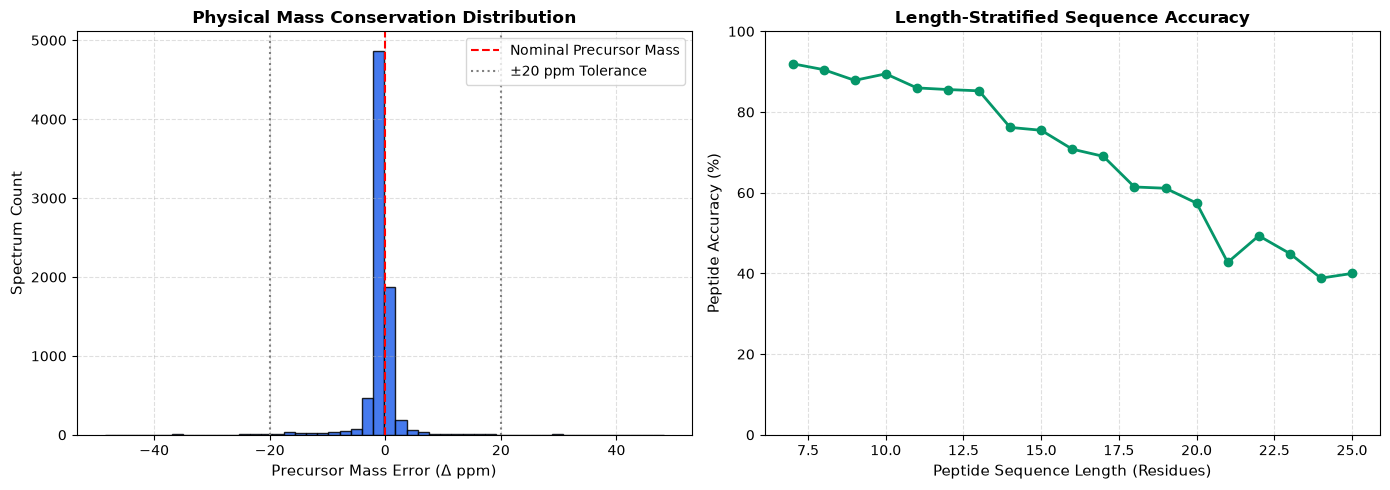

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Precursor Mass Error Distribution (<= 50 ppm window)
ppm_errors = []
for p, t_mass in zip(reranked_preds, [r["precursor_mass"] for r in candidate_records]):
    calc_m = compute_precursor_mass(p)
    ppm = (calc_m - t_mass) / max(1.0, t_mass) * 1e6
    if abs(ppm) <= 50.0:
        ppm_errors.append(ppm)

ax1.hist(ppm_errors, bins=50, color="#2563eb", edgecolor="black", alpha=0.85)
ax1.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Nominal Precursor Mass")
ax1.axvline(-20, color="gray", linestyle=":", label=r"$\pm 20$ ppm Tolerance")
ax1.axvline(20, color="gray", linestyle=":")
ax1.set_xlabel(r"Precursor Mass Error ($\Delta$ ppm)", fontsize=11)
ax1.set_ylabel("Spectrum Count", fontsize=11)
ax1.set_title("Physical Mass Conservation Distribution", fontsize=12, fontweight="bold")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.4)

# 2. Length-Stratified Accuracy
length_bins = range(7, 26)
len_accs = []
len_counts = []
for L in length_bins:
    idxs = [idx for idx, r in enumerate(candidate_records) if r["target_length"] == L]
    if len(idxs) >= 10:
        acc = np.mean([il_match(reranked_preds[i], candidate_records[i]["target"]) for i in idxs]) * 100.0
        len_accs.append((L, acc))

if len_accs:
    ls, accs = zip(*len_accs)
    ax2.plot(ls, accs, marker="o", color="#059669", linewidth=2.0, markersize=6)
    ax2.set_xlabel("Peptide Sequence Length (Residues)", fontsize=11)
    ax2.set_ylabel("Peptide Accuracy (%)", fontsize=11)
    ax2.set_title("Length-Stratified Sequence Accuracy", fontsize=12, fontweight="bold")
    ax2.set_ylim(0, 100)
    ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()
